# Cross-lingual transfer test, Step 1 (social group mention yes/no)

The original train and test files are pooled and split into five folds, stratified by language and label.

| condition | training data | test data |
|---|---|---|
| `within_matched` | target language, other four folds, subsampled to the common size | held-out target fold (5 models) |
| `cross_matched` | source language, subsampled to the same size (new draw per fold) | the same held-out target fold (5 models) |
| `cross_full` | all source-language sentences | all target-language sentences (pushed to Hugging Face) |


In [1]:
%%capture
!pip install -U transformers datasets accelerate

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from huggingface_hub import notebook_login
notebook_login()

In [4]:
import os, json, random, shutil, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, cohen_kappa_score)

# ======== CONFIG ========
DATA_DIR   = "/content/drive/MyDrive/Media_Model_Annotations (1)/Combined"
TRAIN_PATH = f"{DATA_DIR}/train_with_all_outlets_final.json"
TEST_PATH  = f"{DATA_DIR}/test_with_all_outlets_final.json"
OUT_DIR    = "/content/drive/MyDrive/Media_Deservingness_Paper/cross_validation_v2/cross_lingual_step1"

MODEL_NAME   = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
SEED         = 98
K_FOLDS      = 5
MAX_LENGTH   = 256
LR           = 2e-5
BATCH_TRAIN  = 8
BATCH_EVAL   = 64
EPOCHS       = 4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MIXED_PRECISION = False

LANG_MAP   = {"French": "fr", "German": "de"}
DIRECTIONS = [("fr", "de"), ("de", "fr")]
RUN_POOLED = True
N_BOOT     = 2000
RESUME     = True

# Hugging Face
HF_UPLOAD  = True
HF_REPO_TEMPLATE = "selsar/social_group_detection_xling_{direction}"
HF_PRIVATE = True

for d in [OUT_DIR, f"{OUT_DIR}/runs", f"{OUT_DIR}/results", f"{OUT_DIR}/figures"]:
    os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

In [5]:
# ======= Load, pool and fold the data =======
def read_json_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

rows = [dict(r, orig_split="train") for r in read_json_lines(TRAIN_PATH)] + \
       [dict(r, orig_split="test")  for r in read_json_lines(TEST_PATH)]
data = pd.DataFrame(rows)
data["label"] = data["label"].apply(lambda v: 1 if v else 0)          # 1 = mentions a social group
data["lang"]  = data["language"].map(LANG_MAP)
if data["lang"].isna().any():
    print("⚠️ dropping rows with unknown language:",
          data.loc[data.lang.isna(), "language"].value_counts(dropna=False).to_dict())
    data = data[data.lang.notna()]
if "paper" not in data.columns: data["paper"] = "Unknown"
data["paper"] = data["paper"].fillna("Unknown")
data = data.reset_index(drop=True)
data["sentence_id"] = np.arange(len(data))

# identical texts form one group and always share a fold
key = data["text"].astype(str).str.lower().str.split().str.join(" ")
data["group"] = pd.factorize(key)[0]
n_dup = int(data.duplicated("group", keep=False).sum())
print(f"{len(data)} sentences ({(data.orig_split=='train').sum()} train + {(data.orig_split=='test').sum()} test), "
      f"{n_dup} belong to groups of identical texts")


g = data.groupby("group").agg(lang=("lang", "first"), label=("label", "max"), n=("sentence_id", "size")).reset_index()
rng = np.random.RandomState(SEED)
fold_of = {}
for _, s in g.groupby(["lang", "label"]):
    s = s.sample(frac=1.0, random_state=rng)
    load = np.zeros(K_FOLDS)
    for grp, n in zip(s.group, s.n):
        f = int(np.argmin(load)); fold_of[grp] = f; load[f] += n
data["fold"] = data["group"].map(fold_of)
data[["sentence_id", "group", "fold", "lang", "label", "paper", "orig_split"]].to_csv(f"{OUT_DIR}/folds.csv", index=False)

support = data.groupby("lang").agg(n_sentences=("label", "size"), n_pos=("label", "sum"))
support["share_pos"] = (support.n_pos / support.n_sentences).round(3)
print(support.to_string())
print(data.groupby(["lang", "fold"]).label.agg(["size", "sum"]).unstack("fold").to_string())

6300 sentences (5040 train + 1260 test), 21 belong to groups of identical texts
      n_sentences  n_pos  share_pos
lang                               
de           1800    498      0.277
fr           4500   1251      0.278
     size                      sum                    
fold    0    1    2    3    4    0    1    2    3    4
lang                                                  
de    361  361  360  359  359  100  100  100   99   99
fr    901  900  900  900  899  251  250  250  250  250


In [6]:
# ======= Size matching =======
def common_size(src, tgt):
    """Positives and negatives per training set: the smaller of the full source set and the smallest
    four-fold target pool, matched separately for positives and negatives."""
    S = data[data.lang == src]; T = data[data.lang == tgt]
    pools = [T[T.fold != f] for f in range(K_FOLDS)]
    n_pos = min(int(S.label.sum()), min(int(p.label.sum()) for p in pools))
    n_neg = min(int((S.label == 0).sum()), min(int((p.label == 0).sum()) for p in pools))
    return n_pos, n_neg

def subsample(pool, n_pos, n_neg, seed):
    r = np.random.RandomState(seed)
    pos = pool[pool.label == 1].sentence_id.values; neg = pool[pool.label == 0].sentence_id.values
    return set(int(i) for i in r.choice(pos, n_pos, replace=False)) | \
           set(int(i) for i in r.choice(neg, n_neg, replace=False))

for s, t in DIRECTIONS:
    n_pos, n_neg = common_size(s, t)
    print(f"{s}->{t}: common training size {n_pos + n_neg} sentences ({n_pos} with a group mention)")

fr->de: common training size 1439 sentences (398 with a group mention)
de->fr: common training size 1800 sentences (498 with a group mention)


In [7]:
# ======= Metrics =======
def metrics(y, prob):
    y = np.asarray(y).astype(int); prob = np.asarray(prob); pred = (prob > 0.5).astype(int)
    return dict(n=len(y), n_pos=int(y.sum()),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                f1_weighted=f1_score(y, pred, average="weighted", zero_division=0),
                accuracy=accuracy_score(y, pred),
                kappa=cohen_kappa_score(y, pred) if len(set(y)) > 1 else np.nan,
                pr_auc=average_precision_score(y, prob) if 0 < y.sum() < len(y) else np.nan)

def boot_ci(y, prob, n_boot=N_BOOT, seed=SEED, keys=("precision", "recall", "f1", "pr_auc")):
    r = np.random.RandomState(seed); y = np.asarray(y); prob = np.asarray(prob); out = {k: [] for k in keys}
    for _ in range(n_boot):
        i = r.randint(0, len(y), len(y)); m = metrics(y[i], prob[i])
        for k in keys: out[k].append(m[k])
    return {f"{k}_{b}": float(np.nanpercentile(v, q)) for k, v in out.items() for b, q in (("lo", 2.5), ("hi", 97.5))}

In [8]:
# ======= One training run =======
LOCAL_TMP = "/content/tmp_step1_xling"

def train_and_predict(train_ids, test_ids, run_name, seed):
    import torch
    from datasets import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                              Trainer, TrainingArguments, set_seed)
    set_seed(seed)
    tr = data[data.sentence_id.isin(train_ids)].sample(frac=1.0, random_state=seed)
    te = data[data.sentence_id.isin(test_ids)].copy()
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True)

    model = model.float()
    assert next(model.parameters()).dtype == torch.float32
    enc = lambda b: tok(b["text"], truncation=True, max_length=MAX_LENGTH)
    ds_tr = Dataset.from_pandas(tr[["text", "label"]].reset_index(drop=True)).map(enc, batched=True)
    ds_te = Dataset.from_pandas(te[["text", "label"]].reset_index(drop=True)).map(enc, batched=True)
    bf16 = MIXED_PRECISION and torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    fp16 = MIXED_PRECISION and torch.cuda.is_available() and not bf16
    warmup_steps = int(np.ceil(WARMUP_RATIO * EPOCHS * np.ceil(len(tr) / BATCH_TRAIN)))
    args = TrainingArguments(output_dir=f"{LOCAL_TMP}/{run_name}", eval_strategy="no", save_strategy="no",
                             learning_rate=LR, per_device_train_batch_size=BATCH_TRAIN,
                             per_device_eval_batch_size=BATCH_EVAL, num_train_epochs=EPOCHS,
                             weight_decay=WEIGHT_DECAY, warmup_steps=warmup_steps,
                             seed=seed, report_to=[], logging_steps=50, bf16=bf16, fp16=fp16)
    trainer = Trainer(model=model, args=args, train_dataset=ds_tr, data_collator=DataCollatorWithPadding(tok))
    trainer.train()
    logits = trainer.predict(ds_te).predictions
    logits = logits[0] if isinstance(logits, (tuple, list)) else logits
    logits = logits.astype(np.float64)
    e = np.exp(logits - logits.max(1, keepdims=True)); prob = (e / e.sum(1, keepdims=True))[:, 1]
    te["prob_group"] = prob; te["pred"] = (prob > 0.5).astype(int)
    log = pd.DataFrame(trainer.state.log_history)
    model_out = trainer.model.to("cpu"); del trainer; torch.cuda.empty_cache()
    shutil.rmtree(f"{LOCAL_TMP}/{run_name}", ignore_errors=True)
    cols = ["sentence_id", "text", "label", "pred", "prob_group", "lang", "paper", "fold", "orig_split"]
    return te[cols], log, model_out, tok

In [9]:
# ======= Run plan =======
PLAN = []
for s, t in DIRECTIONS:
    n_pos, n_neg = common_size(s, t); tag = f"{s}2{t}"
    S = data[data.lang == s]; T = data[data.lang == t]
    for f in range(K_FOLDS):
        test_ids = set(int(i) for i in T[T.fold == f].sentence_id)
        PLAN.append(dict(run=f"{tag}__within_matched__fold{f}", direction=tag, condition="within_matched", fold=f,
                         train_ids=subsample(T[T.fold != f], n_pos, n_neg, SEED + f), test_ids=test_ids, seed=SEED + f))
        PLAN.append(dict(run=f"{tag}__cross_matched__fold{f}", direction=tag, condition="cross_matched", fold=f,
                         train_ids=subsample(S, n_pos, n_neg, SEED + 100 + f), test_ids=test_ids, seed=SEED + 100 + f))
    PLAN.append(dict(run=f"{tag}__cross_full", direction=tag, condition="cross_full", fold=-1,
                     train_ids=set(int(i) for i in S.sentence_id), test_ids=set(int(i) for i in T.sentence_id), seed=SEED))
if RUN_POOLED:
    for f in range(K_FOLDS):
        PLAN.append(dict(run=f"both__pooled_full__fold{f}", direction="both", condition="pooled_full", fold=f,
                         train_ids=set(int(i) for i in data[data.fold != f].sentence_id),
                         test_ids=set(int(i) for i in data[data.fold == f].sentence_id), seed=SEED + 200 + f))

def comp(ids):
    d = data[data.sentence_id.isin(ids)]
    return {"n_train": len(d), "n_train_pos": int(d.label.sum()),
            "n_train_fr": int((d.lang == "fr").sum()), "n_train_de": int((d.lang == "de").sum())}
manifest = pd.DataFrame([{**{k: v for k, v in p.items() if k not in ("train_ids", "test_ids")},
                          **comp(p["train_ids"]), "n_test": len(p["test_ids"])} for p in PLAN])
manifest.to_csv(f"{OUT_DIR}/results/run_manifest.csv", index=False)
print(f"{len(PLAN)} training runs"); print(manifest.drop(columns=["seed"]).to_string(index=False))

27 training runs
                         run direction      condition  fold  n_train  n_train_pos  n_train_fr  n_train_de  n_test
fr2de__within_matched__fold0     fr2de within_matched     0     1439          398           0        1439     361
 fr2de__cross_matched__fold0     fr2de  cross_matched     0     1439          398        1439           0     361
fr2de__within_matched__fold1     fr2de within_matched     1     1439          398           0        1439     361
 fr2de__cross_matched__fold1     fr2de  cross_matched     1     1439          398        1439           0     361
fr2de__within_matched__fold2     fr2de within_matched     2     1439          398           0        1439     360
 fr2de__cross_matched__fold2     fr2de  cross_matched     2     1439          398        1439           0     360
fr2de__within_matched__fold3     fr2de within_matched     3     1439          398           0        1439     359
 fr2de__cross_matched__fold3     fr2de  cross_matched     3     1439   

In [10]:
# ======= MAIN (resumable): predictions, training log and a full record per run; cross_full pushed to HF =======
def push(p, model, tok, info, log):
    import tempfile
    from huggingface_hub import HfApi, create_repo
    repo = HF_REPO_TEMPLATE.format(direction=p["direction"]); src, tgt = p["direction"][:2], p["direction"][-2:]
    name = {"fr": "French", "de": "German"}
    create_repo(repo, exist_ok=True, private=HF_PRIVATE)
    model.push_to_hub(repo, private=HF_PRIVATE, commit_message=f"Upload {p['run']}")
    tok.push_to_hub(repo, private=HF_PRIVATE, commit_message="Upload tokenizer")
    m = info["test"]
    card = f"""---
base_model: {MODEL_NAME}
language: [{src}, {tgt}]
pipeline_tag: text-classification
tags: [soccat, social-groups, cross-lingual]
---

# SOCCAT Step 1 (social group mention detection), trained on {name[src]} only

Binary classifier (label 1 = the sentence mentions a social group), fine-tuned from `{MODEL_NAME}` on the
{info['n_train']} {name[src]} annotated sentences only ({info['n_train_pos']} with a group mention). Released as part of
the cross-lingual transfer test of the SOCCAT pipeline. No {name[tgt]} data was used for training or model selection.

Out-of-language performance on {int(m['n'])} {name[tgt]} sentences ({int(m['n_pos'])} with a group mention), threshold 0.5:
precision {m['precision']:.3f}, recall {m['recall']:.3f}, F1 {m['f1']:.3f}, PR-AUC {m['pr_auc']:.3f}.
"""
    with tempfile.TemporaryDirectory() as td:
        open(f"{td}/README.md", "w").write(card)
        json.dump(info, open(f"{td}/training_info.json", "w"), indent=2, default=str)
        log.to_csv(f"{td}/training_log.csv", index=False)
        HfApi().upload_folder(repo_id=repo, folder_path=td, commit_message="Model card and training record")
    return f"https://huggingface.co/{repo}"

for p in PLAN:
    out_csv, info_js = f"{OUT_DIR}/runs/{p['run']}__predictions.csv", f"{OUT_DIR}/runs/{p['run']}__info.json"
    wants_hf = HF_UPLOAD and p["condition"] == "cross_full"
    if RESUME and os.path.exists(out_csv) and os.path.exists(info_js):
        if not wants_hf or json.load(open(info_js)).get("hf_repo"):
            print("skip (done):", p["run"]); continue
    print(f"\n========== {p['run']}: train {len(p['train_ids'])}, test {len(p['test_ids'])} ==========")
    pred, log, model, tok = train_and_predict(p["train_ids"], p["test_ids"], p["run"], p["seed"])
    # sanity check: a healthy run ends well below the loss of always guessing the class shares (about 0.59)
    # and predicts both classes; otherwise do not save it, so it is retrained when the cell is rerun
    losses = log["loss"].dropna() if "loss" in log.columns else pd.Series(dtype=float)
    final_loss = float(losses.tail(3).mean()) if len(losses) else np.nan
    if (pred["pred"].nunique() < 2 or not (final_loss > 0 and final_loss < 0.45)
            or not np.isfinite(pred["prob_group"]).all()):
        print(f"❌ {p['run']} looks collapsed (final training loss {final_loss:.3f}, "
              f"predicted classes {sorted(int(v) for v in pred['pred'].unique())}). Not saved. "
              "Check that the model is trained in fp32 (MIXED_PRECISION = False), then rerun this cell.")
        del model; continue
    for k in ("run", "direction", "condition"): pred[k] = p[k]
    pred.to_csv(out_csv, index=False); log.to_csv(f"{OUT_DIR}/runs/{p['run']}__training_log.csv", index=False)
    info = {**{k: v for k, v in p.items() if k not in ("train_ids", "test_ids")}, **comp(p["train_ids"]),
            "n_test": len(p["test_ids"]), "base_model": MODEL_NAME, "epochs": EPOCHS, "lr": LR,
            "batch_train": BATCH_TRAIN, "max_length": MAX_LENGTH, "mixed_precision": MIXED_PRECISION,
            "final_training_loss": final_loss,
            "test": {k: (None if pd.isna(v) else float(v)) for k, v in metrics(pred.label, pred.prob_group).items()},
            "hf_repo": None}
    if wants_hf:
        try:
            info["hf_repo"] = push(p, model, tok, info, log); print("✅ pushed to", info["hf_repo"])
        except Exception as e:
            print(f"⚠️ push failed ({e}); rerun this cell to retry, predictions are kept")
    json.dump(info, open(info_js, "w"), indent=2, default=str)
    del model
    print({k: round(v, 3) for k, v in info["test"].items() if k in ("precision", "recall", "f1", "pr_auc") and v is not None})

summary = pd.json_normalize([json.load(open(f)) for f in sorted(glob.glob(f"{OUT_DIR}/runs/*__info.json"))])
summary.to_csv(f"{OUT_DIR}/results/run_summary.csv", index=False)
print(summary[["run", "n_train", "n_train_pos", "test.f1", "test.pr_auc", "hf_repo"]].round(3).to_string(index=False))


========== fr2de__within_matched__fold0: train 1439, test 361 ==========


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

...

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Map:   0%|          | 0/1439 [00:00<?, ? examples/s]

Map:   0%|          | 0/361 [00:00<?, ? examples/s]

Step,Training Loss
50,0.624119
100,0.612106
150,0.534357
200,0.462935
250,0.404147
300,0.375139
350,0.425319
400,0.220922
450,0.287149
500,0.220354


{'precision': 0.859, 'recall': 0.55, 'f1': 0.671, 'pr_auc': 0.803}
skip (done): fr2de__within_matched__fold1
skip (done): fr2de__cross_matched__fold1
skip (done): fr2de__within_matched__fold2
skip (done): fr2de__cross_matched__fold2
skip (done): fr2de__within_matched__fold3
skip (done): fr2de__cross_matched__fold3
skip (done): fr2de__within_matched__fold4
skip (done): fr2de__cross_matched__fold4
skip (done): fr2de__cross_full
skip (done): de2fr__within_matched__fold0
skip (done): de2fr__cross_matched__fold0
skip (done): de2fr__within_matched__fold1
skip (done): de2fr__cross_matched__fold1
skip (done): de2fr__within_matched__fold2
skip (done): de2fr__cross_matched__fold2
skip (done): de2fr__within_matched__fold3
skip (done): de2fr__cross_matched__fold3
skip (done): de2fr__within_matched__fold4
skip (done): de2fr__cross_matched__fold4
skip (done): de2fr__cross_full
skip (done): both__pooled_full__fold0
skip (done): both__pooled_full__fold1
skip (done): both__pooled_full__fold2
skip (done

In [11]:
# ======= Results per direction and condition, and the paired gap =======
missing = [p["run"] for p in PLAN if not os.path.exists(f"{OUT_DIR}/runs/{p['run']}__predictions.csv")]
if missing:
    raise RuntimeError(f"{len(missing)} runs missing or collapsed, rerun the MAIN cell first: {missing}")
P = pd.concat([pd.read_csv(f) for f in glob.glob(f"{OUT_DIR}/runs/*__predictions.csv")], ignore_index=True)

rows, gaps = [], []
for s, t in DIRECTIONS:
    tag = f"{s}2{t}"
    conds = {c: P[(P.direction == tag) & (P.condition == c)] for c in ["within_matched", "cross_matched", "cross_full"]}
    conds["pooled_full"] = P[(P.condition == "pooled_full") & (P.lang == t)]
    for c, d in conds.items():
        if d.empty: continue
        assert d.sentence_id.is_unique, f"{tag} {c}: a sentence was predicted twice"
        rows.append(dict(direction=tag, condition=c, **metrics(d.label, d.prob_group), **boot_ci(d.label, d.prob_group)))
    w = conds["within_matched"][["sentence_id", "label", "prob_group"]]
    c = conds["cross_matched"][["sentence_id", "prob_group"]]
    m = w.merge(c, on="sentence_id", suffixes=("_w", "_c"))
    y, pw, pc = m.label.values, m.prob_group_w.values, m.prob_group_c.values
    r = np.random.RandomState(SEED); bf, bpr, brc, bpa = [], [], [], []
    for _ in range(N_BOOT):
        i = r.randint(0, len(y), len(y)); a, b = metrics(y[i], pw[i]), metrics(y[i], pc[i])
        bf.append(a["f1"] - b["f1"]); bpr.append(a["precision"] - b["precision"])
        brc.append(a["recall"] - b["recall"]); bpa.append(a["pr_auc"] - b["pr_auc"])
    a, b = metrics(y, pw), metrics(y, pc)
    q = lambda v: np.nanpercentile(v, [2.5, 97.5])
    gaps.append(dict(direction=tag, n_test=len(y), n_test_pos=int(y.sum()),
                     f1_within=a["f1"], f1_cross=b["f1"], f1_gap=a["f1"] - b["f1"], f1_gap_lo=q(bf)[0], f1_gap_hi=q(bf)[1],
                     precision_gap=a["precision"] - b["precision"], precision_gap_lo=q(bpr)[0], precision_gap_hi=q(bpr)[1],
                     recall_gap=a["recall"] - b["recall"], recall_gap_lo=q(brc)[0], recall_gap_hi=q(brc)[1],
                     prauc_within=a["pr_auc"], prauc_cross=b["pr_auc"], prauc_gap=a["pr_auc"] - b["pr_auc"],
                     prauc_gap_lo=q(bpa)[0], prauc_gap_hi=q(bpa)[1],
                     retention=b["f1"] / a["f1"] if a["f1"] else np.nan))
res = pd.DataFrame(rows); gaps = pd.DataFrame(gaps)
res.to_csv(f"{OUT_DIR}/results/step1_crosslingual_results.csv", index=False)
gaps.to_csv(f"{OUT_DIR}/results/step1_crosslingual_paired_gaps.csv", index=False)
print(res[["direction", "condition", "n", "n_pos", "precision", "recall", "f1", "f1_lo", "f1_hi", "pr_auc"]]
      .round(3).to_string(index=False))
print(); print(gaps.round(3).to_string(index=False))

ov = []
for s, t in DIRECTIONS:
    tag = f"{s}2{t}"; R = res[res.direction == tag].set_index("condition"); G = gaps[gaps.direction == tag].iloc[0]
    ov.append(dict(category="Step 1: any social group", direction=tag, n_labels=1,
                   n_test_sentences=int(R.loc["within_matched", "n"]), n_test_pos=int(R.loc["within_matched", "n_pos"]),
                   microf1_within=R.loc["within_matched", "f1"], microf1_within_lo=R.loc["within_matched", "f1_lo"],
                   microf1_within_hi=R.loc["within_matched", "f1_hi"],
                   microf1_cross=R.loc["cross_matched", "f1"], microf1_cross_lo=R.loc["cross_matched", "f1_lo"],
                   microf1_cross_hi=R.loc["cross_matched", "f1_hi"],
                   microf1_gap=G.f1_gap, microf1_gap_lo=G.f1_gap_lo, microf1_gap_hi=G.f1_gap_hi, retention=G.retention))
pd.DataFrame(ov).to_csv(f"{OUT_DIR}/results/step1_crosslingual_overview.csv", index=False)

direction      condition    n  n_pos  precision  recall    f1  f1_lo  f1_hi  pr_auc
    fr2de within_matched 1800    498      0.746   0.791 0.768  0.739  0.797   0.789
    fr2de  cross_matched 1800    498      0.850   0.546 0.665  0.627  0.700   0.767
    fr2de     cross_full 1800    498      0.872   0.586 0.701  0.666  0.734   0.825
    fr2de    pooled_full 1800    498      0.789   0.833 0.811  0.784  0.835   0.851
    de2fr within_matched 4500   1251      0.759   0.836 0.795  0.777  0.813   0.805
    de2fr  cross_matched 4500   1251      0.680   0.857 0.758  0.741  0.775   0.735
    de2fr     cross_full 4500   1251      0.655   0.909 0.762  0.744  0.778   0.789
    de2fr    pooled_full 4500   1251      0.797   0.879 0.836  0.821  0.851   0.868

direction  n_test  n_test_pos  f1_within  f1_cross  f1_gap  f1_gap_lo  f1_gap_hi  precision_gap  precision_gap_lo  precision_gap_hi  recall_gap  recall_gap_lo  recall_gap_hi  prauc_within  prauc_cross  prauc_gap  prauc_gap_lo  prauc_gap_hi  re

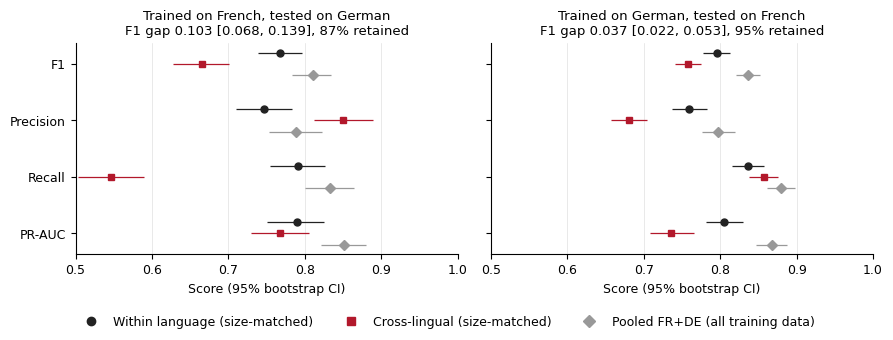

In [12]:
# ======= Figure, Step 1 =======
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
TITLE = {"fr2de": "Trained on French, tested on German", "de2fr": "Trained on German, tested on French"}
STYLE = {"within_matched": dict(marker="o", color="#222222", label="Within language (size-matched)"),
         "cross_matched":  dict(marker="s", color="#B2182B", label="Cross-lingual (size-matched)"),
         "pooled_full":    dict(marker="D", color="#999999", label="Pooled FR+DE (all training data)")}
METRICS = [("f1", "F1"), ("precision", "Precision"), ("recall", "Recall"), ("pr_auc", "PR-AUC")]
conds = [c for c in STYLE if c in set(res.condition)]
off = np.linspace(-0.2, 0.2, len(conds))
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.4), sharey=True)
for ax, (s, t) in zip(axes, DIRECTIONS):
    tag = f"{s}2{t}"
    for j, c in enumerate(conds):
        r = res[(res.direction == tag) & (res.condition == c)]
        if r.empty: continue
        r = r.iloc[0]
        for i, (k, _) in enumerate(METRICS):
            ax.errorbar(r[k], i + off[j], xerr=[[r[k] - r[f"{k}_lo"]], [r[f"{k}_hi"] - r[k]]],
                        fmt=STYLE[c]["marker"], color=STYLE[c]["color"], ms=5, lw=0.9, zorder=3)
    g = gaps[gaps.direction == tag].iloc[0]
    ax.set_title(f"{TITLE[tag]}\nF1 gap {g.f1_gap:.3f} [{g.f1_gap_lo:.3f}, {g.f1_gap_hi:.3f}], "
                 f"{g.retention:.0%} retained", fontsize=9.5); ax.set_xlim(0.5, 1.0); ax.grid(axis="x", lw=0.4, alpha=0.5)
    ax.set_xlabel("Score (95% bootstrap CI)")
axes[0].set_yticks(range(len(METRICS))); axes[0].set_yticklabels([n for _, n in METRICS]); axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], marker=STYLE[c]["marker"], color=STYLE[c]["color"], ls="", label=STYLE[c]["label"])
                    for c in conds], loc="lower center", ncol=len(conds), frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
for ext in ("png", "pdf"): fig.savefig(f"{OUT_DIR}/figures/fig_step1_crosslingual.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## Optional: by outlet

Within-language and cross-lingual F1 per outlet of the target language, to check whether the transfer gap is driven
by particular newspapers.

In [13]:
rows = []
for s, t in DIRECTIONS:
    tag = f"{s}2{t}"
    for c in ["within_matched", "cross_matched"]:
        d = P[(P.direction == tag) & (P.condition == c)]
        for paper, g in d.groupby("paper"):
            rows.append(dict(direction=tag, condition=c, paper=paper, **metrics(g.label, g.prob_group)))
by_outlet = (pd.DataFrame(rows).pivot_table(index=["direction", "paper"], columns="condition",
                                            values=["f1", "n_pos"]).round(3))
by_outlet.to_csv(f"{OUT_DIR}/results/step1_crosslingual_by_outlet.csv")
print(by_outlet.to_string())

                                           f1                        n_pos               
condition                       cross_matched within_matched cross_matched within_matched
direction paper                                                                          
de2fr     Figaro                        0.779          0.785          70.0           70.0
          Le Monde                      0.792          0.831          91.0           91.0
          Le Monde Diplomatique         0.784          0.832         384.0          384.0
          Libération                    0.674          0.734         262.0          262.0
          Médiapart                     0.776          0.806         364.0          364.0
          Parisien                      0.810          0.757          79.0           79.0
          Unknown                       0.000          1.000           1.0            1.0
fr2de     Bild                          0.434          0.694          55.0           55.0
          